# Part II - Prosper Loan Data: Key Insights into Interest Rates

## by Sathvika Kasam

## Investigation Overview

This presentation explores the characteristics of Prosper loans that help explain differences in borrower interest rates. The analysis focuses primarily on the relationship between borrower interest rates, original loan amounts, and loan terms.

The exploratory analysis revealed that borrower interest rates are concentrated within a specific range, generally decrease as the original loan amount increases, and vary across different loan terms. The explanatory analysis presents these findings using three polished visualizations to communicate the most important patterns clearly.


## Dataset Overview and Executive Summary

The Prosper Loan dataset contains 113,937 loan records and 81 variables. Each record represents a loan and includes information about loan characteristics, borrower financial attributes, credit information, and loan status.

The dataset was obtained from the Prosper Loan Data provided by Udacity.

### Key Findings

- Borrower interest rates are concentrated mainly between approximately 8% and 30%, with several noticeable peaks.
- Larger original loan amounts are generally associated with lower borrower interest rates.
- The relationship between loan amount and interest rate remains visible across different loan terms.
- Thirty-six-month loans have the highest median borrower interest rate and the widest distribution of rates.
- Loan amount shows a stronger relationship with borrower interest rate than loan term does.

In [2]:
# Import required packages and set plots to be embedded inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress warnings from final output
import warnings
warnings.simplefilter("ignore")

# Set a consistent visual style
sns.set_style("whitegrid")

# Display plots inside the notebook
%matplotlib inline

In [3]:
# Load the Prosper Loan dataset

df = pd.read_csv("prosperLoanData.csv")

# Display the dataset dimensions
print("Dataset shape:", df.shape)

Dataset shape: (113937, 81)


In [4]:
# Select variables required for the explanatory analysis

analysis_cols = [
    'LoanStatus',
    'BorrowerRate',
    'LoanOriginalAmount',
    'IsBorrowerHomeowner',
    'Term'
]

df_core = df[analysis_cols].dropna().copy()

print("Number of observations:", len(df_core))

Number of observations: 113937


## 1. Distribution of Borrower Interest Rates

The distribution of borrower interest rates provides context for the remaining analysis. Most loans have interest rates within a relatively concentrated range, while a smaller number of loans have substantially higher rates.

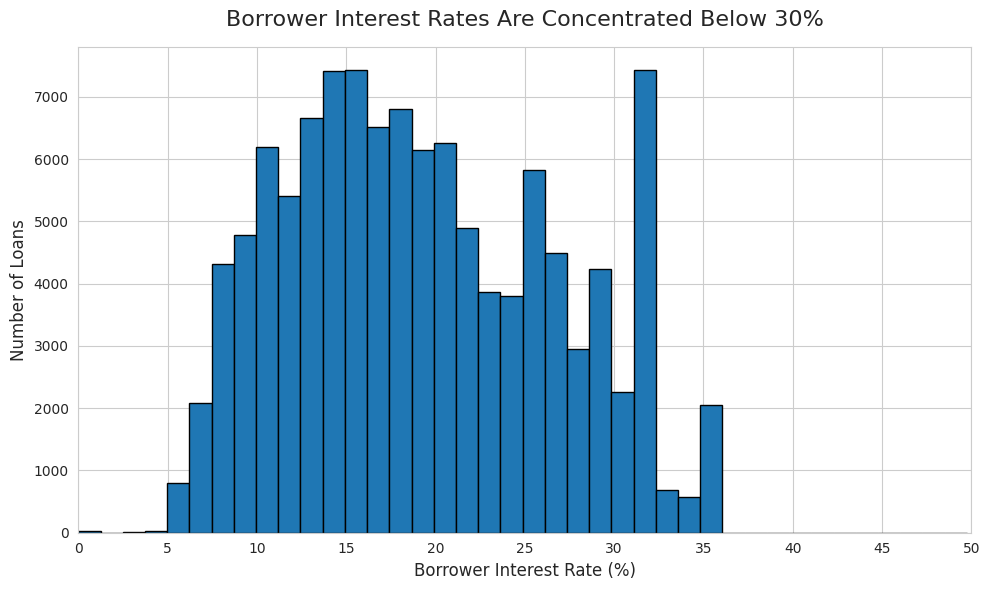

In [5]:
# Plot the distribution of borrower interest rates

plt.figure(figsize=(10, 6))

plt.hist(
    df_core['BorrowerRate'] * 100,
    bins=40,
    edgecolor='black'
)

plt.title(
    'Borrower Interest Rates Are Concentrated Below 30%',
    fontsize=16,
    pad=15
)

plt.xlabel('Borrower Interest Rate (%)', fontsize=12)
plt.ylabel('Number of Loans', fontsize=12)

plt.xticks(np.arange(0, 51, 5))
plt.xlim(0, 50)

plt.tight_layout()
plt.show()

**Key Insight:** Most Prosper loans have borrower interest rates between approximately 8% and 30%. The distribution contains several peaks, while rates above 35% are relatively uncommon. This establishes the typical range of borrowing costs before examining how loan characteristics relate to interest rates.

## 2. Loan Amount and Borrower Interest Rate

The exploratory analysis identified a moderate negative relationship between original loan amount and borrower interest rate. This visualization focuses on that relationship to determine whether larger loans tend to receive lower interest rates.

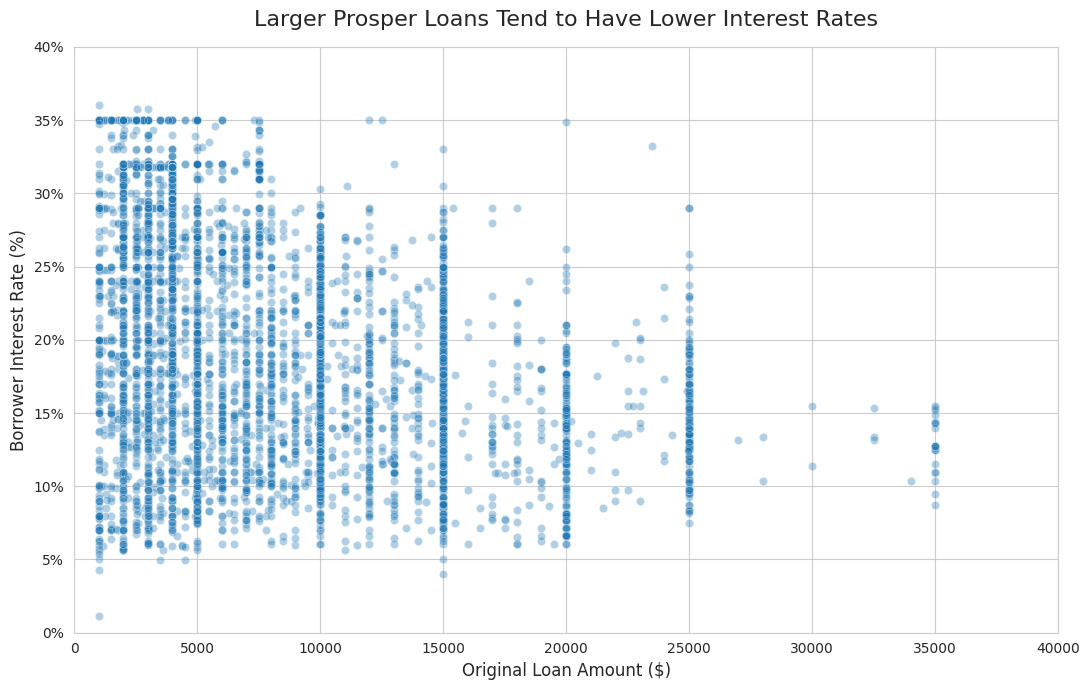

In [6]:
# Create a sample to reduce overplotting while preserving the overall pattern

plot_sample = df_core.sample(
    n=5000,
    random_state=42
)

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=plot_sample,
    x='LoanOriginalAmount',
    y='BorrowerRate',
    alpha=0.35,
    s=35
)

plt.title(
    'Larger Prosper Loans Tend to Have Lower Interest Rates',
    fontsize=16,
    pad=15
)

plt.xlabel('Original Loan Amount ($)', fontsize=12)
plt.ylabel('Borrower Interest Rate (%)', fontsize=12)

# Convert decimal rates to percentages
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f'{y * 100:.0f}%')
)

plt.xticks(
    np.arange(0, 40001, 5000)
)

plt.xlim(0, 40000)
plt.ylim(0, 0.40)

plt.tight_layout()
plt.show()

**Key Insight:** Larger Prosper loans generally tend to have lower borrower interest rates, confirming the moderate negative relationship found during exploration.
Smaller loans show a much wider range of interest rates, including many of the highest rates in the dataset.
As loan amounts increase beyond approximately $15,000, observations become more concentrated toward lower interest rates.
The relationship is not perfectly linear, indicating that other borrower or loan characteristics also influence interest rates.

## 3. Interest Rates Across Loan Terms

Loan terms show different distributions of borrower interest rates. This visualization compares the typical rate and variability for 12-, 36-, and 60-month loans.

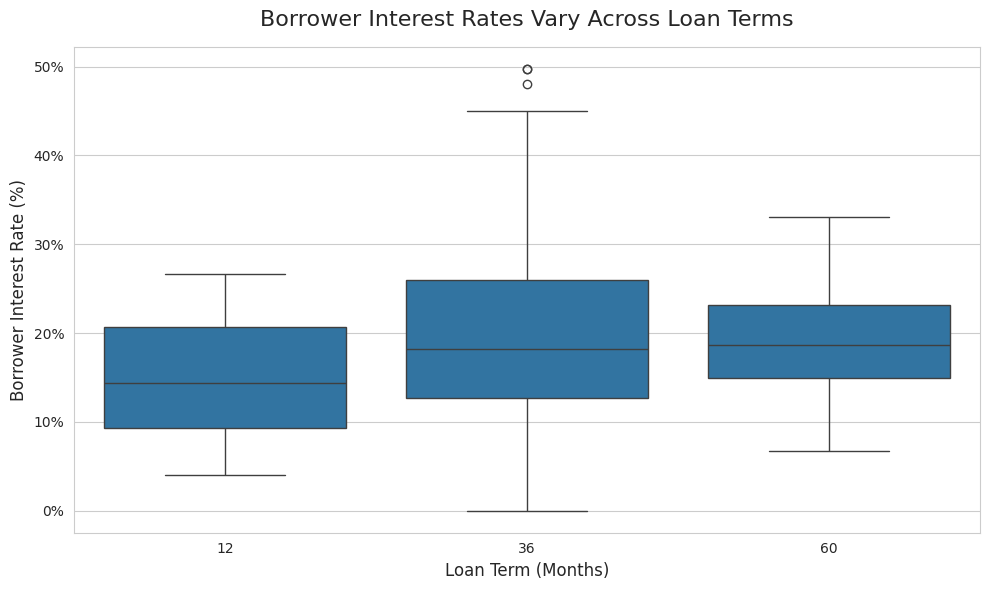

In [7]:
# Plot borrower interest rate distributions by loan term

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_core,
    x='Term',
    y='BorrowerRate'
)

plt.title(
    'Borrower Interest Rates Vary Across Loan Terms',
    fontsize=16,
    pad=15
)

plt.xlabel('Loan Term (Months)', fontsize=12)
plt.ylabel('Borrower Interest Rate (%)', fontsize=12)

# Convert decimal rates to percentages
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f'{y * 100:.0f}%')
)

plt.xticks([0, 1, 2], ['12', '36', '60'])

plt.tight_layout()
plt.show()

**Key Insight:** The 60-month loans have the highest median borrower interest rate, although it is only slightly above the 36-month median.
The 36-month loans have the widest distribution, extending from near 0% to approximately 50%, with several high-rate outliers.
The 12-month loans have the lowest median interest rate and a comparatively narrower distribution.
Overall, loan term is associated with differences in the level and variability of borrower interest rates.

## Investigation Overview

This analysis investigates how loan characteristics are associated with borrower interest rates in the Prosper Loan dataset. The main focus is on understanding the distribution of interest rates and examining how they vary with original loan amount and loan term.

The analysis highlights three key findings:

1. Borrower interest rates are concentrated mainly between 8% and 30%, with several noticeable peaks.
2. Larger loans generally tend to have lower borrower interest rates, although the relationship is not perfectly linear.
3. Borrower interest rates vary across loan terms, with 60-month loans having a slightly higher median rate and 36-month loans showing the greatest variability.

Together, these findings show that loan amount and loan term are important characteristics associated with differences in borrower interest rates.

## Dataset Overview and Executive Summary

The Prosper Loan dataset contains 113,937 loan records and 81 variables. Each record represents an individual loan and includes information about loan characteristics, borrower financial attributes, credit information, and loan status.

The dataset was provided by Prosper and is included in the Udacity Data Visualization project resources.

The exploratory analysis was used to identify the most important patterns, which were then refined into three explanatory visualizations:

- **Interest Rate Distribution:** Most borrower interest rates fall between approximately 8% and 30%.
- **Loan Amount and Interest Rate:** Larger loans generally have lower borrower interest rates, while smaller loans show considerably greater variation.
- **Loan Term and Interest Rate:** Interest-rate distributions differ across loan terms, with 60-month loans having the highest median and 36-month loans showing the widest spread.

These visualizations focus on the strongest and most interpretable relationships discovered during the exploratory analysis.